# Coding 5: Estimate annual observations and forecast a future year

QIDIAN XING  
MICHAEL SUHERMAN  
GUS GUENTHER  
ENDI ZONANA

MGMTMFE 431 Homework 1. Six-notebook organization: October 5, 2026.

**Formal task:** validate the annual MLE on 3000 simulated months, fit monthly and annual historical observations independently, and compare three forecasts on the same 913 entirely future twelve-month targets.

This notebook is independent: start its kernel in this directory and use Restart Kernel → Run All. No other notebook or project module is required. AI assistance is disclosed in the separate submission record.

## Parameters and fixed seeds

Monthly rates are in percentage points. Q and H are variances. Experimental settings are unchanged from the verified project.

In [1]:
from dataclasses import dataclass
from pathlib import Path
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from numba import njit
from scipy.optimize import minimize
from IPython.display import display, HTML

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.2, 'figure.dpi': 120,
})
COLORS = {'monthly': '#1e4e79', 'annual': '#9b4b2b',
          'benchmark': '#52665f', 'data': '#454545'}

In [2]:
CONFIG = {'true_parameters': {'mu': 0.2, 'phi': 0.9, 'Q': 0.04, 'H': 0.01},
 'sample_lengths': [300, 3000, 300000],
 'simulation_seeds': [431300, 4313000, 431300000],
 'economic_simulation_seeds': [43101, 43102, 43103, 43104],
 'economic_sample_length': 936,
 'optimizer': {'initial_phi': [-0.5, 0.3, 0.8, 0.95],
               'maxiter': 1200,
               'gtol': 1e-08,
               'gradient_step': 1e-05},
 'hessian_steps': [0.002, 0.001, 0.0005],
 'input_csv': '../data/US_inflation47_25.csv',
 'monte_carlo': {'sample_length': 936,
                 'replications': 200,
                 'master_seed': 20261003,
                 'gradient_tolerance': 1e-06,
                 'parameter_valid_definition': 'Finite interior estimate, finite full '
                                               'likelihood, selected actual average '
                                               'gradient infinity norm < 1e-6. Optimizer '
                                               'flag is counted separately.',
                 'se_valid_definition': 'Parameter-valid plus returned fit; positive '
                                        'full-likelihood Hessian; finite positive SEs; '
                                        'original gradient and <2% step-stability criteria '
                                        'pass for all four parameters.',
                 'denominator_rule': 'All primary calibration columns use the same '
                                     'all-parameter SE-valid complete-case set; companion '
                                     'columns describe all parameter-valid estimates.',
                 'provenance': 'User-directed review extension inspired by Chinese lecture '
                               'guide p.19, not an added formal homework requirement.'}}

## Methods

The 24-state construction is repeated here so this notebook needs no earlier notebook. The two fits use their own observation information sets and unconditional stationary priors.

### Innovation likelihood and model-based asymptotic SEs

Before observing $y_t$, form $a_{t|t-1}$ and $P_{t|t-1}$. After receiving
$y_t$, compute its innovation and likelihood **before** updating the state:
$$v_t=y_t-\mu-a_{t|t-1},\quad F_t=P_{t|t-1}+H,\quad K_t=P_{t|t-1}/F_t.$$
$$a_{t|t}=a_{t|t-1}+K_tv_t,\quad P_{t|t}=P_{t|t-1}H/F_t.$$
$$a_{t+1|t}=\phi a_{t|t},\quad P_{t+1|t}=\phi^2P_{t|t}+Q,$$
$$\ell(\theta)=-\tfrac12\sum_t[\log(2\pi)+\log F_t+v_t^2/F_t].$$

BFGS minimizes the average negative likelihood from four data-derived starts.
The unconstrained coordinates are $u=(\mu,b,\log Q,\log H)$ with
$\phi=\tanh b$. SEs use the Hessian $I_u=\nabla_u^2[-\ell(u)]$ of the
**actual full likelihood**, including derivatives of its stationary prior.
No optimizer inverse-Hessian approximation or pseudoinverse supplies inference.
$$g=(\mu,\phi,\sqrt Q,\sqrt H),\quad
J=\operatorname{diag}(1,1-\phi^2,\sqrt Q/2,\sqrt H/2),$$
$$\operatorname{Cov}(\widehat g)=JI_u^{-1}J',\qquad
\operatorname{SE}(\widehat g_j)=\sqrt{[JI_u^{-1}J']_{jj}}.$$
An average-likelihood Hessian would require multiplication by the observation
count. Three central-difference scales check positive curvature and SE stability;
the middle scale supplies the reported covariance. These are model-based
**asymptotic Hessian/delta-method SEs**, not finite-sample exact or robust SEs.

For annual observations replace the scalar innovation by
    $v_t=z_t-12\mu-Z^{aug}a^{aug}_{t|t-1}$ and its variance by
    $F_t=Z^{aug}P^{aug}_{t|t-1}(Z^{aug})'$, because $H^{aug}=0$.
    The prior is the unconditional joint lag distribution constructed below.
    The same sum of innovation likelihood contributions estimates the monthly parameters.

In [3]:
@dataclass(frozen=True)
class Parameters:
    mu: float
    phi: float
    Q: float
    H: float

    def __post_init__(self):
        if not (abs(self.phi) < 1 and self.Q > 0 and self.H > 0):
            raise ValueError("Require |phi|<1, Q>0 and H>0")

    def vector(self):
        return np.array([self.mu, self.phi, self.Q, self.H])

    def reported(self):
        return np.array([self.mu, self.phi, np.sqrt(self.Q), np.sqrt(self.H)])

In [4]:
def simulate(T_sample, p, seed):
    """Use a stationary initial draw and independent state/observation shocks."""
    rng = np.random.default_rng(seed)
    alpha = np.empty(T_sample)
    alpha[0] = rng.normal(0, np.sqrt(p.Q / (1 - p.phi**2)))
    epsilon = rng.normal(0, np.sqrt(p.Q), T_sample - 1)
    eta = rng.normal(0, np.sqrt(p.H), T_sample)
    for t in range(1, T_sample):
        alpha[t] = p.phi * alpha[t-1] + epsilon[t-1]
    return p.mu + alpha + eta, alpha, eta

In [5]:
def rolling_sum(y, window=12):
    """Complete windows only; keep every monthly observation date."""
    return np.convolve(np.asarray(y), np.ones(window), mode="valid")

In [6]:
def augmented_matrices(p):
    A_phi = np.zeros((12, 12))
    A_zero = np.zeros((12, 12))
    A_phi[0, 0] = p.phi
    for i in range(1, 12):
        A_phi[i, i-1] = A_zero[i, i-1] = 1
    T = np.zeros((24, 24))
    T[:12, :12], T[12:, 12:] = A_phi, A_zero
    R = np.zeros((24, 2))
    R[0, 0], R[12, 1] = 1, 1
    P0 = np.zeros((24, 24))
    lag = np.abs(np.arange(12)[:, None] - np.arange(12)[None, :])
    P0[:12, :12] = p.Q/(1-p.phi**2)*p.phi**lag
    P0[12:, 12:] = p.H*np.eye(12)
    return dict(A_phi=A_phi, A_zero=A_zero, Z=np.ones((1, 24)),
                d=np.array([12*p.mu]), H_obs=np.zeros((1, 1)), T=T,
                c=np.zeros(24), R=R, Q_aug=np.diag([p.Q, p.H]),
                a0=np.zeros(24), P0=P0)

In [7]:
def monthly_filter(y, p):
    n = len(y)
    ap, pp, af, pf, v, F = [np.empty(n) for _ in range(6)]
    a, P = 0.0, p.Q / (1 - p.phi**2)
    for t, yt in enumerate(y):
        ap[t], pp[t] = a, P
        v[t], F[t] = yt - p.mu - a, P + p.H
        if F[t] <= 0:
            raise FloatingPointError("Nonpositive innovation variance")
        K = P / F[t]
        af[t], pf[t] = a + K*v[t], P*p.H/F[t]
        a, P = p.phi*af[t], p.phi**2*pf[t] + p.Q
    nll = float(0.5*np.sum(np.log(2*np.pi) + np.log(F) + v*v/F))
    return dict(a_pred=ap, P_pred=pp, a_filter=af, P_filter=pf,
                innovation=v, F=F, nll=nll)

In [8]:
def annual_filter(z, p):
    """Readable matrix reference; exact scalar observation, no jitter."""
    m = augmented_matrices(p)
    T, R, Qa = m['T'], m['R'], m['Q_aug']
    a, P = m['a0'].copy(), m['P0'].copy()
    n = len(z)
    af, pf = np.empty((n, 24)), np.empty((n, 24, 24))
    ap, pp = np.empty_like(af), np.empty_like(pf)
    v, F = np.empty(n), np.empty(n)
    for t, zt in enumerate(z):
        ap[t], pp[t] = a, P
        pz = P.sum(axis=1)
        F[t] = pz.sum()
        v[t] = zt - 12*p.mu - a.sum()
        if F[t] <= 0:
            raise FloatingPointError("Nonpositive annual innovation variance")
        af[t] = a + pz*v[t]/F[t]
        pf[t] = P - np.outer(pz, pz)/F[t]
        pf[t] = (pf[t]+pf[t].T)/2
        a = T@af[t]
        P = T@pf[t]@T.T + R@Qa@R.T
        P = (P+P.T)/2
    nll = float(0.5*np.sum(np.log(2*np.pi)+np.log(F)+v*v/F))
    return dict(a_pred=ap, P_pred=pp, a_filter=af, P_filter=pf,
                innovation=v, F=F, nll=nll)

In [9]:
def monthly_forecast(a_filter, p):
    return 12*p.mu + np.asarray(a_filter)*np.sum(p.phi**np.arange(1, 13))

In [10]:
def annual_forecast(a_filter, p):
    m = augmented_matrices(p)
    loading = (m['Z'] @ np.linalg.matrix_power(m['T'], 12)).ravel()
    return 12*p.mu + np.asarray(a_filter) @ loading

In [11]:
def from_u(u):
    return Parameters(float(u[0]), float(np.tanh(u[1])),
                      float(np.exp(u[2])), float(np.exp(u[3])))

In [12]:
def to_u(p):
    return np.array([p.mu, np.arctanh(p.phi), np.log(p.Q), np.log(p.H)])

In [13]:
@njit(cache=False)
def monthly_nll_fast(y, mu, phi, Q, H):
    a = 0.0
    P = Q / (1 - phi*phi)
    nll = 0.0
    for yt in y:
        v = yt - mu - a
        F = P + H
        if F <= 0 or not np.isfinite(F):
            return np.inf
        nll += 0.5 * (np.log(2*np.pi) + np.log(F) + v*v/F)
        K = P / F
        a = phi * (a + K*v)
        P = phi*phi * (P*H/F) + Q
    return nll

In [14]:
@njit(cache=False)
def annual_nll_fast(z, mu, phi, Q, H):
    """Sparse shift recursion, O(T*24^2), equivalent to the matrix reference."""
    P = np.zeros((24, 24))
    a = np.zeros(24)
    V = Q/(1-phi*phi)
    for i in range(12):
        for j in range(12):
            P[i, j] = V*phi**abs(i-j)
        P[12+i, 12+i] = H
    previous = np.empty(24, np.int64)
    coefficient = np.ones(24)
    for i in range(24):
        previous[i] = i-1
    previous[0], coefficient[0] = 0, phi
    previous[12], coefficient[12] = 12, 0.0
    nll = 0.0
    for zt in z:
        pz = np.zeros(24)
        for i in range(24):
            for j in range(24):
                pz[i] += P[i, j]
        F = pz.sum()
        if F <= 0 or not np.isfinite(F):
            return np.inf
        v = zt - 12*mu - a.sum()
        nll += 0.5*(np.log(2*np.pi)+np.log(F)+v*v/F)
        af = a + pz*v/F
        Pf = P - np.outer(pz, pz)/F
        for i in range(24):
            a[i] = coefficient[i]*af[previous[i]]
            for j in range(24):
                P[i, j] = coefficient[i]*coefficient[j]*Pf[previous[i], previous[j]]
        P[0, 0] += Q
        P[12, 12] += H
    return nll

In [15]:
def gradient(f, x, step=1e-5):
    h = step*np.maximum(1, np.abs(x))
    g = np.empty(len(x))
    for i in range(len(x)):
        e = np.zeros(len(x)); e[i] = h[i]
        g[i] = (f(x+e)-f(x-e))/(2*h[i])
    return g

In [16]:
def hessian(f, x, step):
    h = step*np.maximum(1, np.abs(x))
    M = np.empty((len(x),len(x)))
    f0 = f(x)
    for i in range(len(x)):
        ei = np.zeros(len(x)); ei[i] = h[i]
        M[i,i] = (f(x+ei)-2*f0+f(x-ei))/h[i]**2
        for j in range(i):
            ej = np.zeros(len(x)); ej[j] = h[j]
            M[i,j] = M[j,i] = (f(x+ei+ej)-f(x+ei-ej)-f(x-ei+ej)+f(x-ei-ej))/(4*h[i]*h[j])
    return M

In [17]:
def fit(observations, kind, config, diagnostics=None):
    """Fit the unchanged MLE; optional observer retains diagnostics on failure."""
    data = np.ascontiguousarray(observations, dtype=float)
    core = monthly_nll_fast if kind == 'monthly' else annual_nll_fast
    def full_nll(u):
        # Numerical overflow guards leave the economically relevant region broad.
        if not np.isfinite(u).all() or abs(np.tanh(u[1])) >= 1 or np.any(np.abs(u[2:])>40):
            return 1e100
        p = from_u(u)
        return float(core(data, *p.vector()))
    objective = lambda u: full_nll(u)/len(data)
    cfg = config['optimizer']
    jac = lambda u: gradient(objective, u, cfg['gradient_step'])
    sample_mean = float(data.mean()/(12 if kind == 'annual' else 1))
    # Start variances are data-derived, never copied from the simulation truth.
    variance = float(np.var(data)/(80 if kind == 'annual' else 1))
    starts = []
    records = []
    for phi in cfg['initial_phi']:
        p0 = Parameters(sample_mean, phi, max(variance*0.6*(1-phi**2),1e-4),max(variance*0.4,1e-4))
        u0 = to_u(p0)
        start = time.perf_counter()
        result = minimize(objective,u0,jac=jac,method='BFGS',
                          options={'gtol':cfg['gtol'],'maxiter':cfg['maxiter']})
        records.append(dict(method='BFGS',initial_phi=phi,initial_u=u0.tolist(),
                            success=bool(result.success),message=str(result.message),
                            iterations=int(result.nit),nfev=int(result.nfev),
                            nll=full_nll(result.x),u=result.x.tolist(),
                            gradient_inf=float(np.max(np.abs(jac(result.x)))),
                            seconds=time.perf_counter()-start))
        starts.append(result)
    result = min(starts,key=lambda r:r.fun)
    u = result.x
    p = from_u(u)
    nll = full_nll(u)
    if diagnostics is not None:
        diagnostics(dict(stage='optimization', parameters=dict(mu=p.mu,phi=p.phi,Q=p.Q,H=p.H),
                         reported=p.reported().tolist(), loglik=-nll,
                         optimizer_success=bool(result.success), optimizer_message=str(result.message),
                         gradient_average_inf=float(np.max(np.abs(jac(u)))),
                         optimization_runs=records))
    hs = [hessian(full_nll,u,s) for s in config['hessian_steps']]
    I = hs[1]
    eigenvalues = np.linalg.eigvalsh(I)
    if diagnostics is not None:
        diagnostics(dict(stage='curvature',hessian=I.tolist(),eigenvalues=eigenvalues.tolist(),
                         condition_number=float(np.linalg.cond(I))))
    if eigenvalues.min() <= 0:
        raise RuntimeError(f'{kind}: actual likelihood Hessian is not positive definite: {eigenvalues}')
    covariance_u = np.linalg.solve(I,np.eye(4))
    J = np.diag([1,1-p.phi**2,np.sqrt(p.Q)/2,np.sqrt(p.H)/2])
    covariance_g = J@covariance_u@J.T
    se = np.sqrt(np.diag(covariance_g))
    Jv = np.diag([1,1-p.phi**2,p.Q,p.H])
    se_variance = np.sqrt(np.diag(Jv@covariance_u@Jv.T))
    variants = [np.sqrt(np.diag(J@np.linalg.solve(h,np.eye(4))@J.T)) for h in hs]
    se_relative_change = float(max(np.max(np.abs(v/se-1)) for v in variants))
    grad = gradient(full_nll,u,config['optimizer']['gradient_step'])
    diag = dict(hessian_steps=config['hessian_steps'],hessian=I.tolist(),
                eigenvalues=eigenvalues.tolist(),condition_number=float(np.linalg.cond(I)),
                symmetry_error=float(np.max(np.abs(I-I.T))),
                hessian_relative_changes=[float(np.linalg.norm(h-I)/np.linalg.norm(I)) for h in hs],
                se_relative_change=se_relative_change,gradient_full=grad.tolist(),
                gradient_average_inf=float(np.max(np.abs(grad))/len(data)),
                covariance_u=covariance_u.tolist(),covariance_reported=covariance_g.tolist(),
                reliable=bool(se_relative_change<0.02 and np.max(np.abs(grad))/len(data)<1e-6))
    if diagnostics is not None:
        diagnostics(dict(stage='inference',se=se.tolist(),inference=diag))
    if not diag['reliable']:
        raise RuntimeError(f'{kind}: unreliable inference diagnostics: {diag}')
    return dict(kind=kind,n=len(data),parameters=dict(mu=p.mu,phi=p.phi,Q=p.Q,H=p.H),
                sqrt_Q=np.sqrt(p.Q),sqrt_H=np.sqrt(p.H),se=se.tolist(),
                se_variances=se_variance.tolist(),u=u.tolist(),loglik=-nll,
                phi12=p.phi**12,optimizer_success=bool(result.success),
                optimizer_message=str(result.message),optimization_runs=records,
                inference=diag)

In [18]:
def parameter_table(result, truth=None):
    p = Parameters(**result['parameters'])
    table = pd.DataFrame({'Parameter': ['mu', 'phi', 'sqrt_Q', 'sqrt_H'],
                          'Estimate': p.reported(), 'SE': result['se']})
    if truth is not None:
        table.insert(1, 'True', truth.reported())
    return table


def convergence_table(results):
    return pd.DataFrame([
        {'Fit': name, 'Observations': r['n'], 'Log likelihood': r['loglik'],
         'Optimizer success': r['optimizer_success'],
         'Message': r['optimizer_message'],
         'Average gradient': r['inference']['gradient_average_inf'],
         'Minimum Hessian eigenvalue': min(r['inference']['eigenvalues']),
         'Relative SE step variation': r['inference']['se_relative_change']}
        for name, r in results.items()
    ])


def show_table(frame, digits=6):
    display(HTML(frame.to_html(index=False, float_format=lambda value: f'{value:.{digits}f}')))


def calendar_axis(axis):
    axis.xaxis.set_major_locator(mdates.YearLocator(20))
    axis.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

In [19]:
def dense_monthly_covariance(n,p):
    C=np.empty((n,n))
    for i in range(n):
        for j in range(n):
            C[i,j]=p.Q/(1-p.phi*p.phi)*p.phi**abs(i-j)
            if i==j: C[i,j]+=p.H
    return C

In [20]:
def dense_nll(x,mean,C):
    sign,ld=np.linalg.slogdet(C)
    assert sign==1
    r=x-mean
    return 0.5*(len(x)*np.log(2*np.pi)+ld+r@np.linalg.solve(C,r))

In [21]:
def read_and_audit_csv():
    path = Path('../data/US_inflation47_25.csv')
    if not path.is_file():
        raise FileNotFoundError('Start the kernel in the notebooks directory; the CSV is in ../data/.')
    raw = pd.read_csv(path, usecols=['Date', 'Inflation'])
    dates = pd.to_datetime(raw.Date.astype(str), format='%Y%m')
    expected = pd.date_range('1947-01-01', '2024-12-01', freq='MS')
    assert len(raw) == 936 and dates.tolist() == expected.tolist()
    assert dates.nunique() == 936 and not raw.isna().any().any()
    y = 100 * raw.Inflation.to_numpy(dtype=float)
    assert np.isfinite(y).all()
    z = rolling_sum(y)
    assert len(z) == 925
    audit_table = pd.DataFrame([
        ['Monthly observations', len(y), '1947-01', '2024-12'],
        ['Rolling annual sums', len(z), '1947-12', '2024-12'],
        ['Missing values', int(raw.isna().sum().sum()), '', ''],
        ['Zero monthly observations', int((y == 0).sum()), '', ''],
        ['Negative monthly observations', int((y < 0).sum()), '', ''],
    ], columns=['Check', 'Count', 'First date', 'Last date'])
    return dates, y, z, audit_table

## Verify the annual likelihood and estimate the original simulation

In [22]:
truth = Parameters(**CONFIG['true_parameters'])
# A dense joint Gaussian check is independent of the filter recursion.
check_y, _, _ = simulate(35, truth, 903)
check_z = rolling_sum(check_y)
aggregation = np.zeros((len(check_z), len(check_y)))
for i in range(len(check_z)): aggregation[i,i:i+12] = 1
covariance = aggregation@dense_monthly_covariance(len(check_y),truth)@aggregation.T
dense_value = dense_nll(check_z,12*truth.mu,covariance)
np.testing.assert_allclose(annual_filter(check_z,truth)['nll'],dense_value,atol=1e-8)
np.testing.assert_allclose(annual_nll_fast(check_z,*truth.vector()),dense_value,atol=1e-8)
simulated_y, _, _ = simulate(3000, truth, CONFIG['simulation_seeds'][1])
simulated_z = rolling_sum(simulated_y)
assert len(simulated_z) == 2989
annual_simulation_result = fit(simulated_z, 'annual', CONFIG)
show_table(parameter_table(annual_simulation_result, truth))
show_table(convergence_table({'Annual simulated sums': annual_simulation_result}))

Parameter,True,Estimate,SE
mu,0.200000,0.188257,0.038799
phi,0.900000,0.906278,0.008825
sqrt_Q,0.200000,0.199556,0.005587
sqrt_H,0.100000,0.104441,0.006206


Fit,Observations,Log likelihood,Optimizer success,Message,Average gradient,Minimum Hessian eigenvalue,Relative SE step variation
Annual simulated sums,2989,-20.156074,True,Optimization terminated successfully.,0.000000,60.149349,0.000004


## Read the CSV and estimate both historical fits here

In [23]:
dates, y, z, data_audit = read_and_audit_csv()
display(data_audit)
monthly_result = fit(y, 'monthly', CONFIG)
annual_result = fit(z, 'annual', CONFIG)
monthly_parameters = Parameters(**monthly_result['parameters'])
annual_parameters = Parameters(**annual_result['parameters'])
estimates = []
for name, result in [('Monthly observations', monthly_result),('Annual observations',annual_result)]:
    table = parameter_table(result); table.insert(0,'Fit',name); estimates.append(table)
show_table(pd.concat(estimates,ignore_index=True))
show_table(pd.DataFrame({'Fit':['Monthly','Annual'], 'phi^12':[monthly_parameters.phi**12,annual_parameters.phi**12]}))
show_table(convergence_table({'Monthly data': monthly_result,'Annual data':annual_result}))

,Check,Count,First date,Last date
0,Monthly observations,936,1947-01,2024-12
1,Rolling annual sums,925,1947-12,2024-12
2,Missing values,0,,
3,Zero monthly observations,138,,
4,Negative monthly observations,116,,


Fit,Parameter,Estimate,SE
Monthly observations,mu,0.287164,0.027991
Monthly observations,phi,0.752686,0.053792
Monthly observations,sqrt_Q,0.204315,0.027249
Monthly observations,sqrt_H,0.233854,0.019718
Annual observations,mu,0.287400,0.034214
Annual observations,phi,0.870105,0.046242
Annual observations,sqrt_Q,0.132518,0.027528
Annual observations,sqrt_H,0.259652,0.015379


Fit,phi^12
Monthly,0.033065
Annual,0.188303


Fit,Observations,Log likelihood,Optimizer success,Message,Average gradient,Minimum Hessian eigenvalue,Relative SE step variation
Monthly data,936,-305.104716,True,Optimization terminated successfully.,0.000000,9.303286,0.000012
Annual data,925,-285.055599,True,Optimization terminated successfully.,0.000000,4.660840,0.000022


The annual fit estimates greater latent persistence and smaller state-shock variation. Greater persistence in annual observations can also reflect overlapping windows; it is not by itself evidence of a structural change in the monthly latent process.

## Predict an entirely future twelve-month sum
The target is $z_{t+12}=y_{t+1}+\cdots+y_{t+12}$:
$$\widehat z^m_{t+12|t}=12\widehat\mu_m+a^m_{t|t}\sum_{h=1}^{12}\widehat\phi_m^h,$$
$$\widehat z^a_{t+12|t}=12\widehat\mu_a+Z^{aug}(T^{aug})^{12}a^{aug}_{t|t},\qquad
\widehat z^b_{t+12|t}=z_t.$$
Use only filtered origin states and propagate without intermediate observations.
Monthly origins are December 1947–December 2023. Every method has the same 913
targets, December 1948–December 2024. Predicting the next overlapping annual
sum would retain eleven already-known months and be less revealing.

In [24]:
monthly_states = monthly_filter(y, monthly_parameters)
annual_states = annual_filter(z, annual_parameters)
assert np.all(annual_states['F'] > 0)
assert min(np.linalg.eigvalsh(p).min() for p in annual_states['P_filter']) > -1e-10
origins = np.arange(11, len(y)-12)
annual_origins = np.arange(len(z)-12)
forecasts = pd.DataFrame({
    'origin_date':dates.iloc[origins].dt.strftime('%Y-%m').to_numpy(),
    'target_date':dates.iloc[origins+12].dt.strftime('%Y-%m').to_numpy(),
    'actual':z[12:],
    'monthly_forecast':monthly_forecast(monthly_states['a_filter'][origins],monthly_parameters),
    'annual_forecast':annual_forecast(annual_states['a_filter'][annual_origins],annual_parameters),
    'benchmark_forecast':z[:-12],
})
assert len(forecasts) == 913
assert tuple(forecasts.iloc[0][['origin_date','target_date']]) == ('1947-12','1948-12')
assert tuple(forecasts.iloc[-1][['origin_date','target_date']]) == ('2023-12','2024-12')
metric_rows = []
for method in ['monthly','annual','benchmark']:
    error = forecasts.actual-forecasts[method+'_forecast']
    forecasts[method+'_error'] = error
    metric_rows.append({'method':method,'targets':len(forecasts),
                        'RMSE':float(np.sqrt(np.mean(error**2))), 'MAE':float(np.mean(np.abs(error)))})
forecast_metrics = pd.DataFrame(metric_rows)
show_table(forecast_metrics)

method,targets,RMSE,MAE
monthly,913,2.386592,1.760915
annual,913,2.209205,1.609438
benchmark,913,2.436909,1.672849


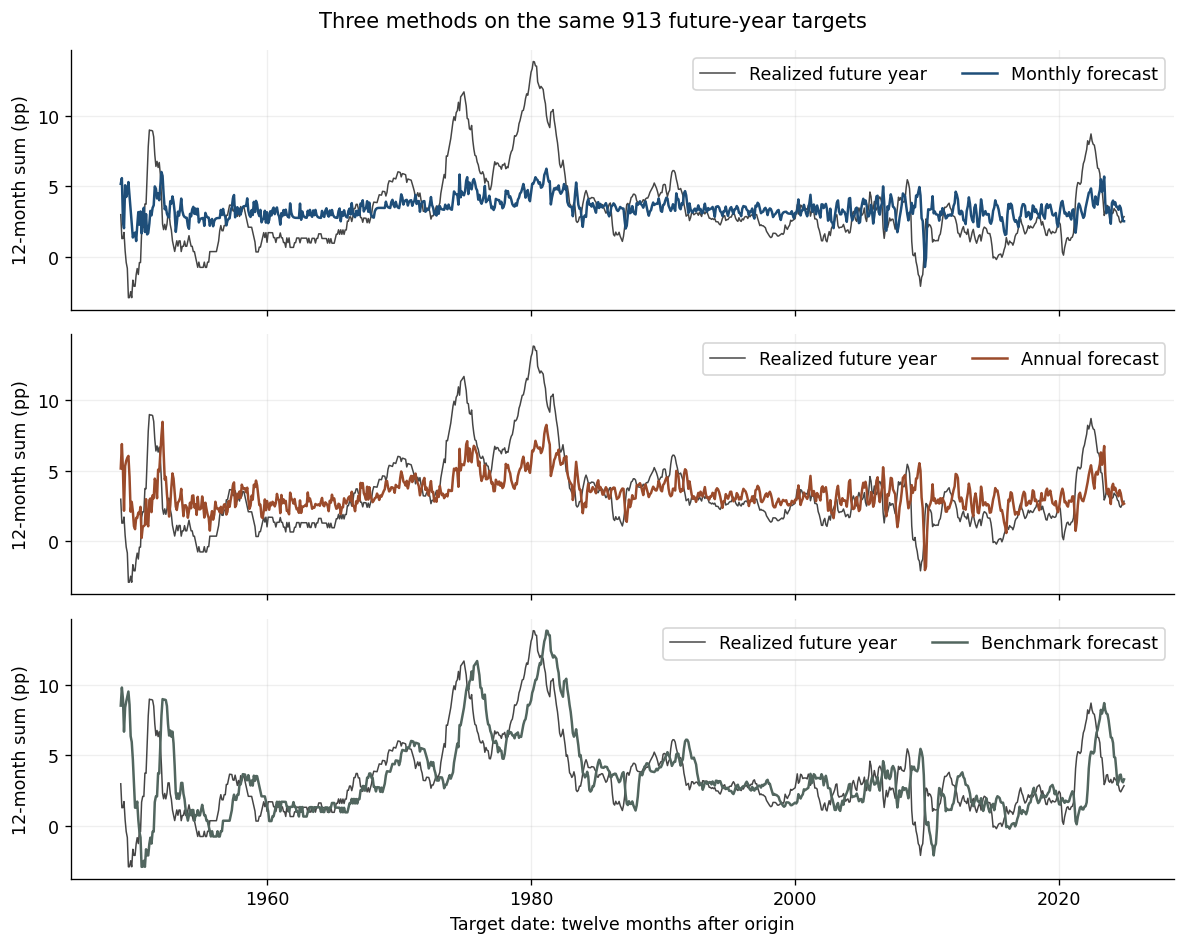

In [25]:
target_dates = pd.to_datetime(forecasts.target_date)
fig_forecasts, axes = plt.subplots(3,1,figsize=(10,8),sharex=True,sharey=True)
for ax, method in zip(axes,['monthly','annual','benchmark']):
    ax.plot(target_dates,forecasts.actual,color=COLORS['data'],lw=0.9,label='Realized future year')
    ax.plot(target_dates,forecasts[method+'_forecast'],color=COLORS[method],label=method.title()+' forecast')
    ax.set_ylabel('12-month sum (pp)'); ax.legend(ncol=2); calendar_axis(ax)
axes[-1].set_xlabel('Target date: twelve months after origin')
fig_forecasts.suptitle('Three methods on the same 913 future-year targets')
fig_forecasts.tight_layout(); plt.show()

Monthly RMSE is lower but MAE is higher than the persistence benchmark; squared loss puts more weight on large misses. The annual fit has lower values of both metrics here, without establishing statistically significant superiority. Full-sample parameters contain later information even though filtered states respect each origin, so this is a **retrospective comparison, not an out-of-sample test**.